# Explore integrations - Amacrine cells

In [2]:
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib import pyplot as plt
import scanpy as sc
# import rapids_singlecell as rsc
import scanpy as rsc
from tqdm import tqdm
from pathlib import Path

sc.set_figure_params(frameon=False, dpi=100, fontsize=12, dpi_save=300)
plt.rcParams["svg.fonttype"] = "none"

import scatlastb_utils as atl

/hpc/scratch/project.hca_integration/miniforge3/envs/scanpy/lib/python3.11/site-packages/louvain/__init__.py:54: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import get_distribution, DistributionNotFound


In [3]:
%load_ext autoreload
%autoreload 2

In [4]:
def clean_prefixes(adata, prefix):
    adata.obs.columns = adata.obs.columns.str.replace(prefix, '')
    
    adata.obsm = {
        key.replace(prefix, ''): adata.obsm[key]
        for key in adata.obsm.keys()
    }
    
    adata.obsp = {
        key.replace(prefix, ''): adata.obsp[key]
        for key in adata.obsp.keys()
    }
    
    adata.uns = {
        key.replace(prefix, ''): adata.uns[key]
        for key in adata.uns.keys()
    }

In [5]:
figure_dir = Path('figures/figure3/F')
figure_dir.mkdir(exist_ok=True, parents=True)

## Read data

In [6]:
adata = atl.io.read_anndata(
    'data/pipeline/HRCA/majority_voting/dataset~AC/file_id~collect:AC.zarr',
    dask=True,
    backed=True,
    obs='obs',
    obsm='obsm',
    # uns='uns',
)

dask: True, backed: True
chunks: (200000, -1)
Read slot "obs", store as "obs"...
Read slot "obsm", store as "obsm"...


Read obsm slots as_dask=False: 100%|██████████| 64/64 [00:14<00:00,  4.38it/s]


shape: (571579, 0)


In [7]:
clean_prefixes(adata, 'metrics:')
# adata

In [8]:
adata.obs['majority_consensus'] = pd.Categorical(
    adata.obs['majority_consensus'],
    categories=adata.obs['ann_finest_level'].cat.categories
)
adata.obs['majority_consensus_disagreement'] = 1 - adata.obs['majority_consensus_agreement']

In [9]:
for col in tqdm(
    adata.obs.select_dtypes(include=["object", "category"])
):
    adata.obs[col] = adata.obs[col].where(
        ~adata.obs[col].astype(str).str.contains("unknown", na=False),
        np.nan
    )

  0%|          | 180/571579 [00:33<29:06:55,  5.45it/s]


## Visualise integrations

In [10]:
colors = [
    # 'ann_finest_level',
    # 'majority_consensus',
    # 'majority_consensus_agreement',
    'majority_consensus_disagreement',
    'scrublet_score',
    'cell_type',
    # 'sex',
    # 'age',
    # 'qc_status',
]

In [1]:
integrations = [
    # 'drvi--strategy=lineage--batch=sample_id--n_hvgs=3000',
    'scvi--strategy=lineage--batch=sample_id--n_hvgs=3000',
    'scvi--strategy=global--batch=sample_id--n_hvgs=3000',
    'scvi--strategy=lineage--batch=sample_id--n_hvgs=1000',
    'scvi--strategy=global--batch=sample_id--n_hvgs=1000',
    # 'harmony--strategy=lineage--batch=sample_id--n_hvgs=3000',
    # 'scpoli--strategy=lineage--batch=sample_id--n_hvgs=3000',
    'scpoli--strategy=global--batch=sample_id--n_hvgs=1000',
]

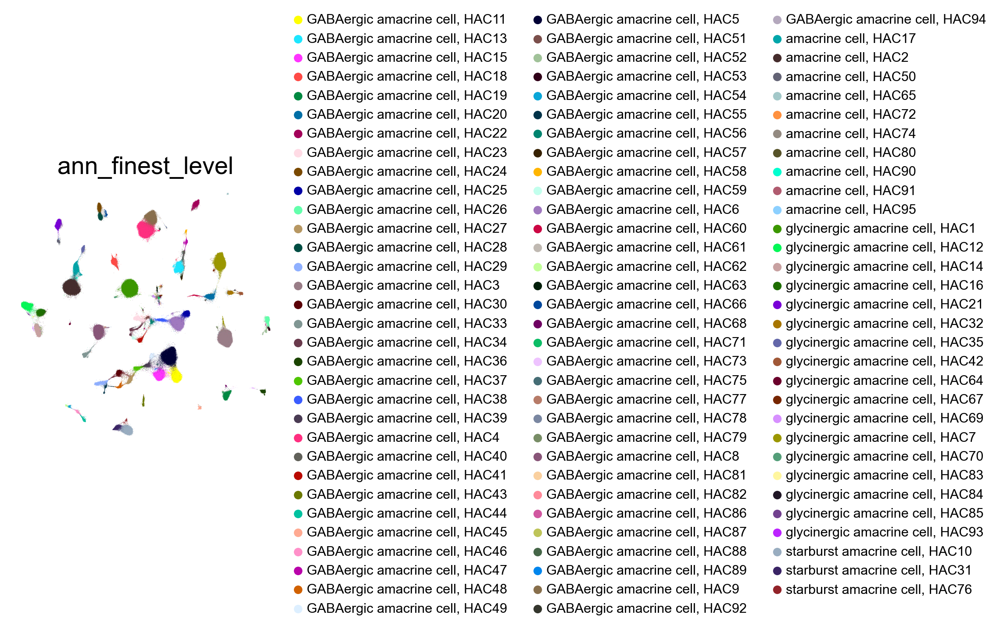

In [12]:
sc.pl.embedding(
    adata,
    basis=f'X_umap--{integrations[0]}',
    color='ann_finest_level',
)

In [13]:
adata.uns["majority_consensus_colors"] = adata.uns["ann_finest_level_colors"]

Plotting colors:   0%|          | 0/1 [00:00<?, ?it/s]

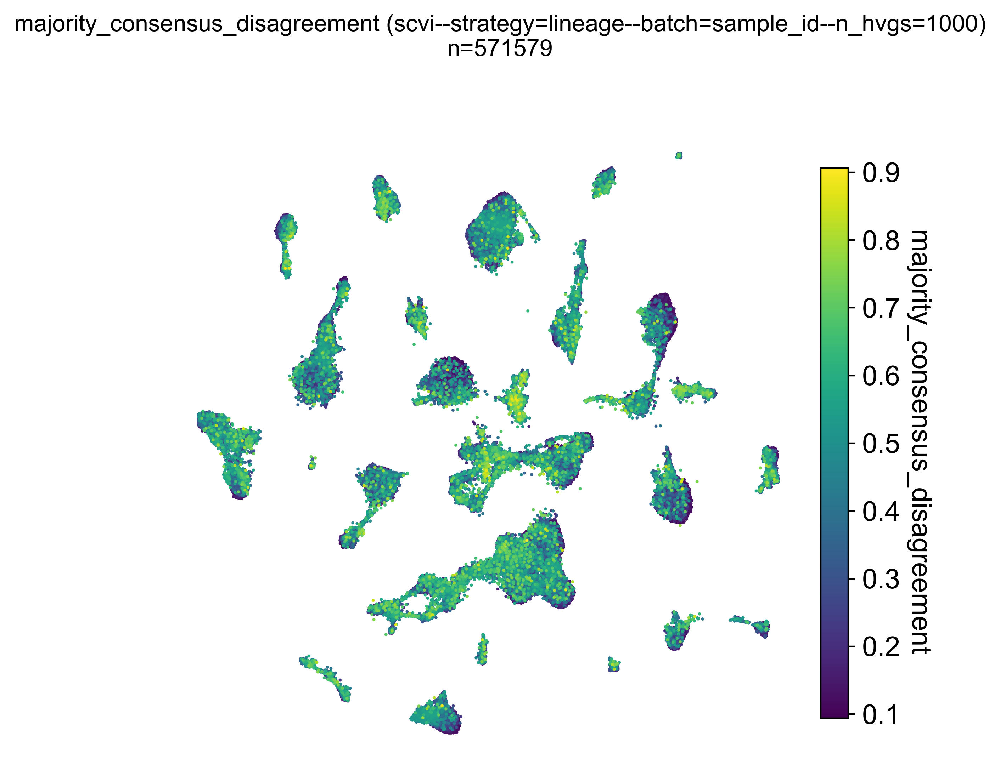

Plotting colors:   0%|          | 0/1 [00:00<?, ?it/s]

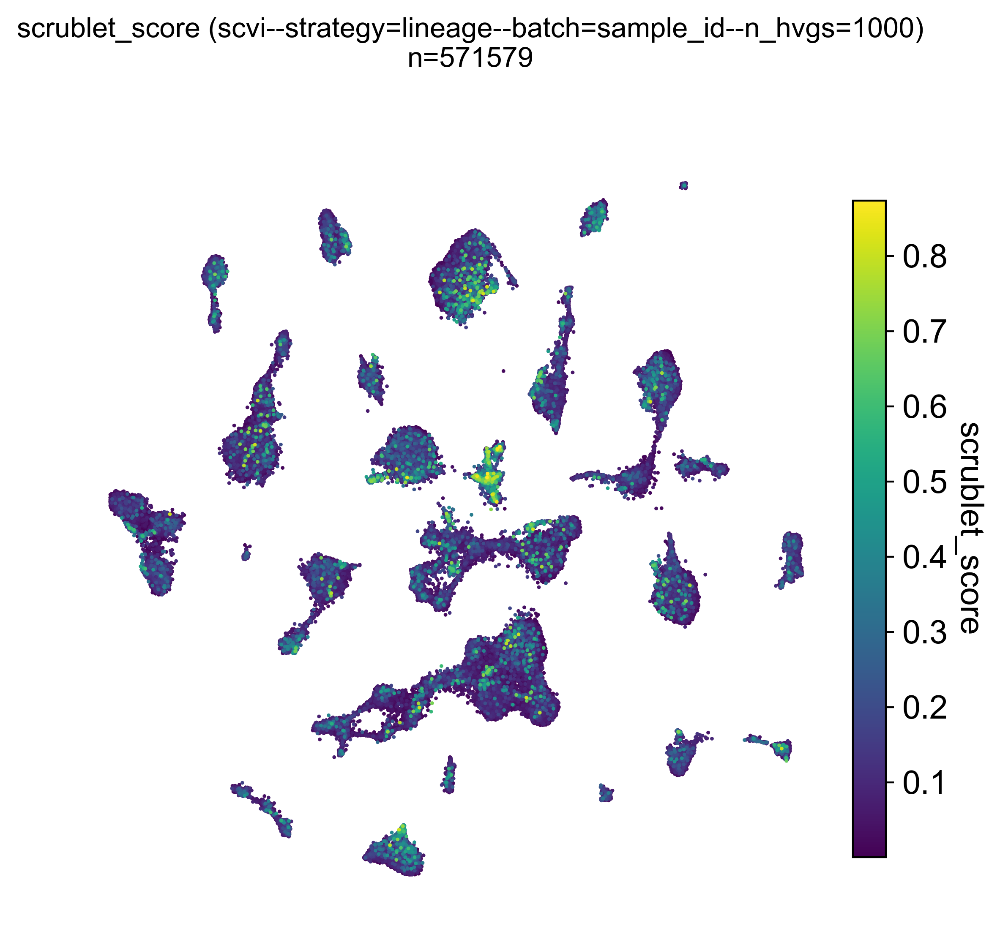

Plotting colors:   0%|          | 0/1 [00:00<?, ?it/s]

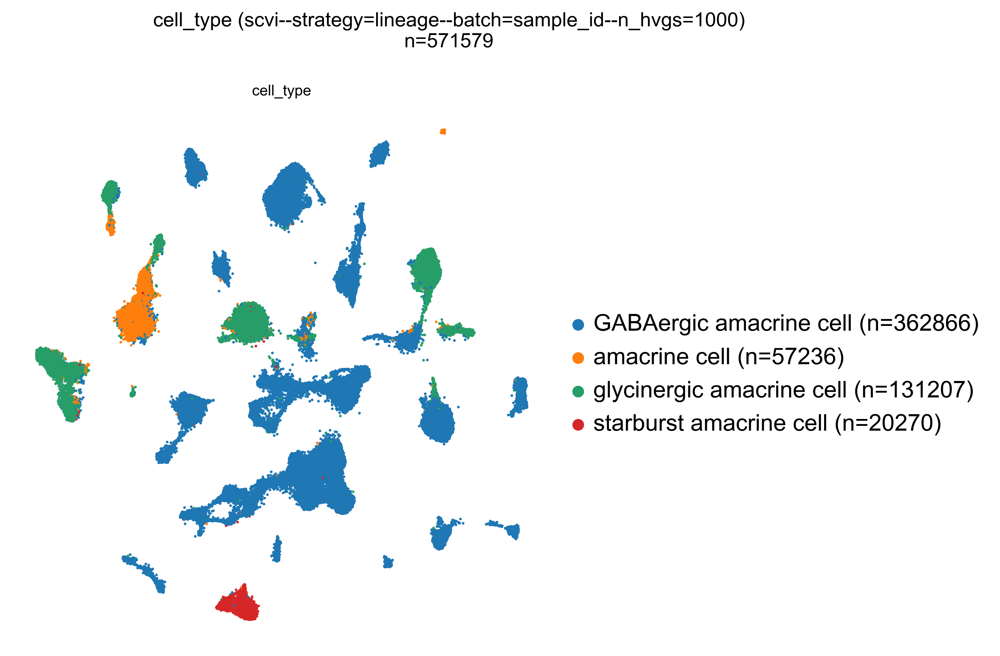

Plotting colors:   0%|          | 0/1 [00:00<?, ?it/s]

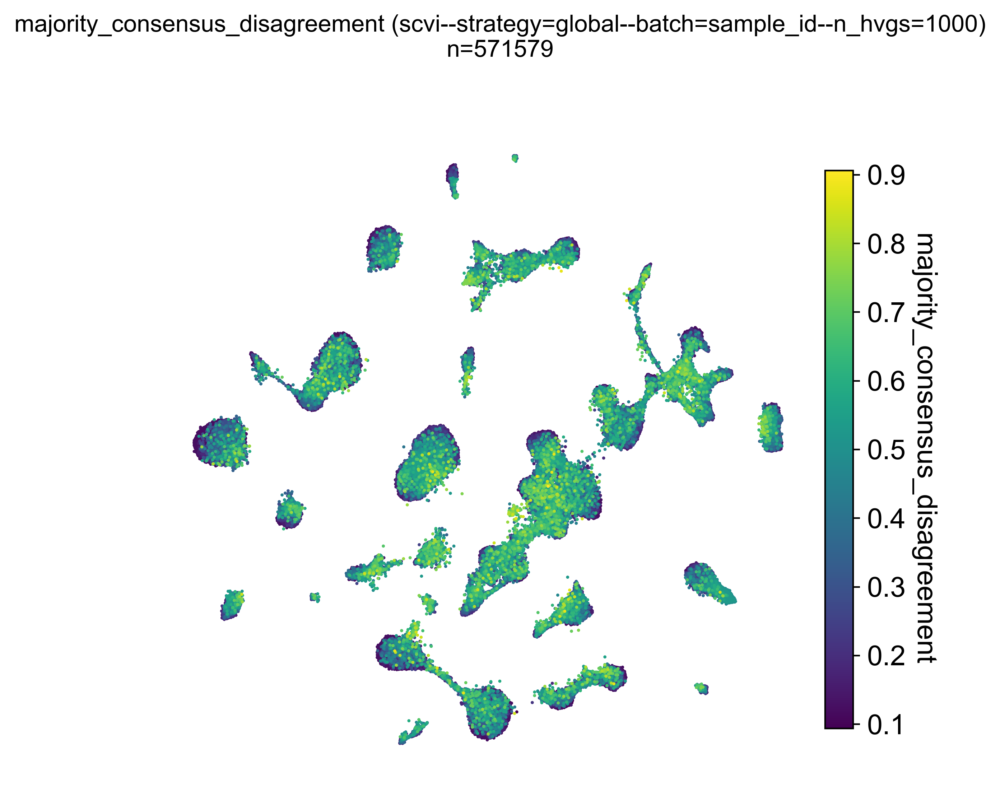

Plotting colors:   0%|          | 0/1 [00:00<?, ?it/s]

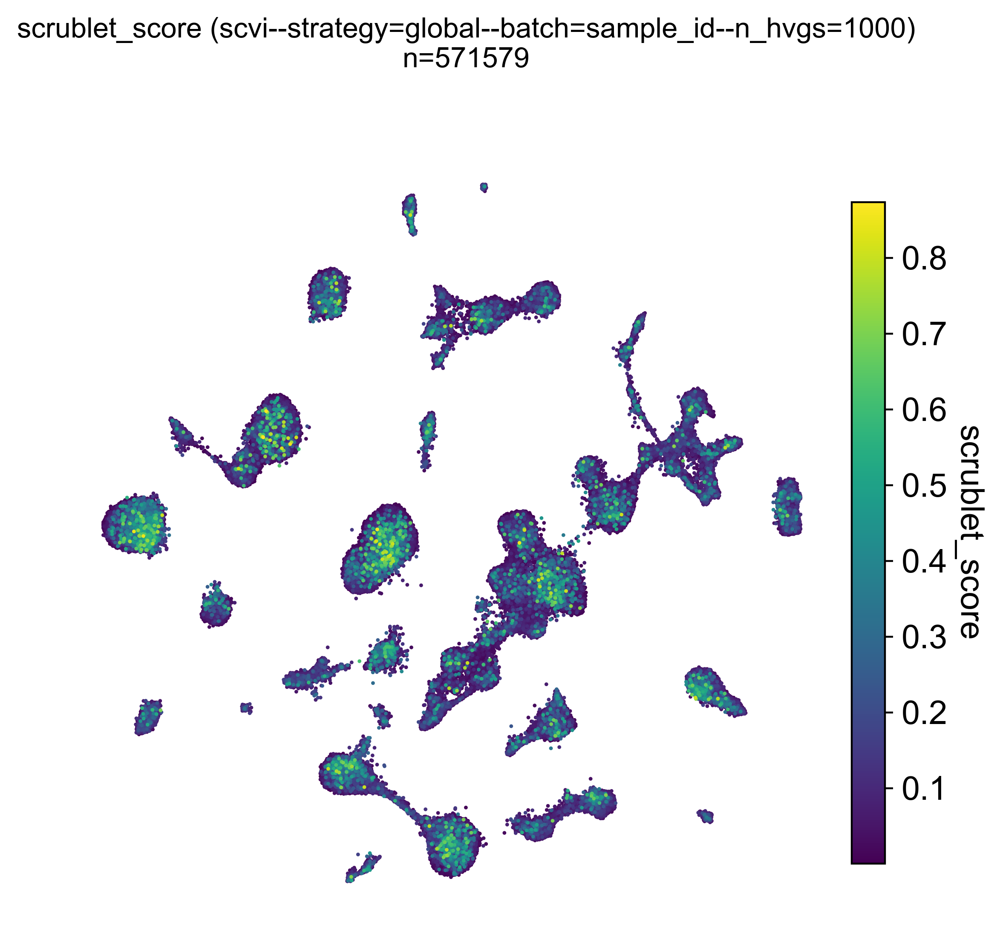

Plotting colors:   0%|          | 0/1 [00:00<?, ?it/s]

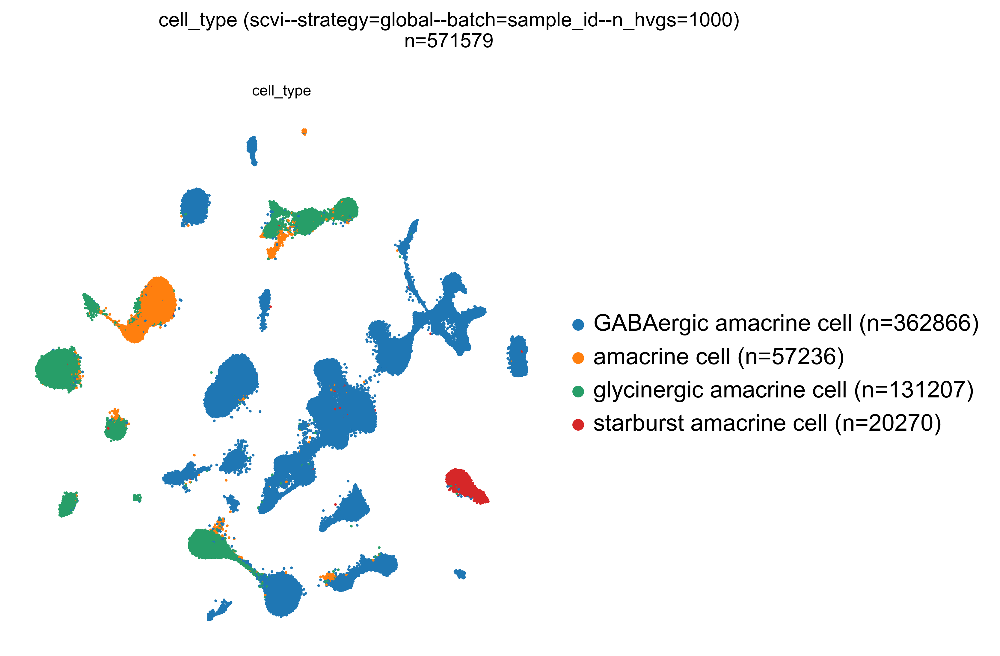

Plotting colors:   0%|          | 0/1 [00:00<?, ?it/s]

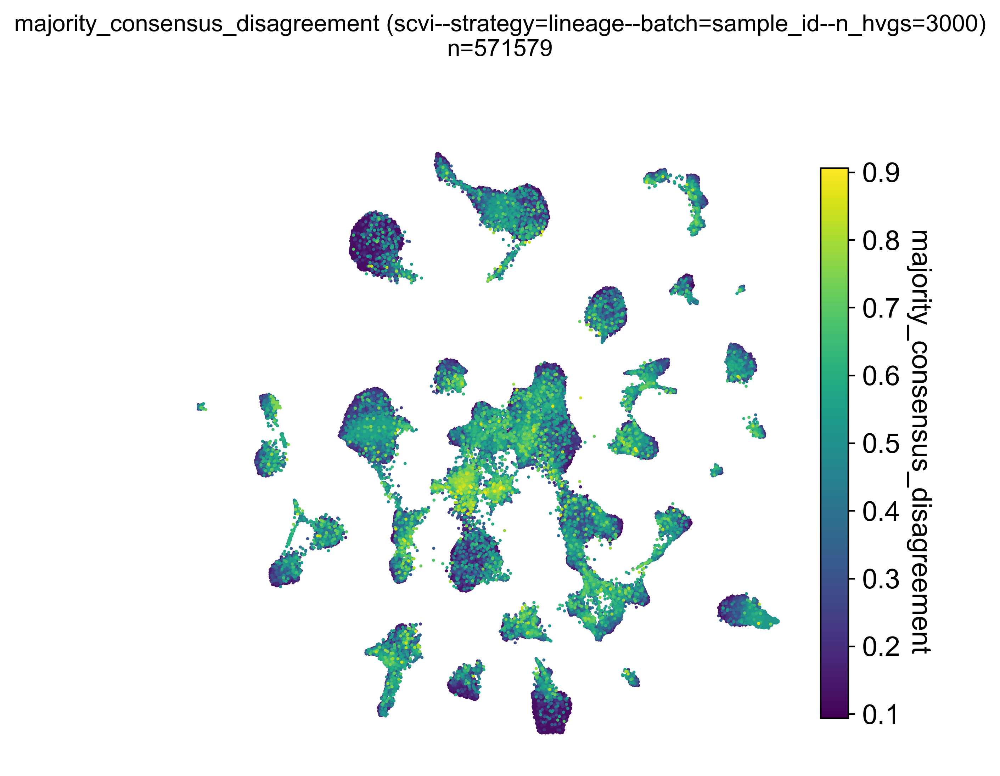

Plotting colors:   0%|          | 0/1 [00:00<?, ?it/s]

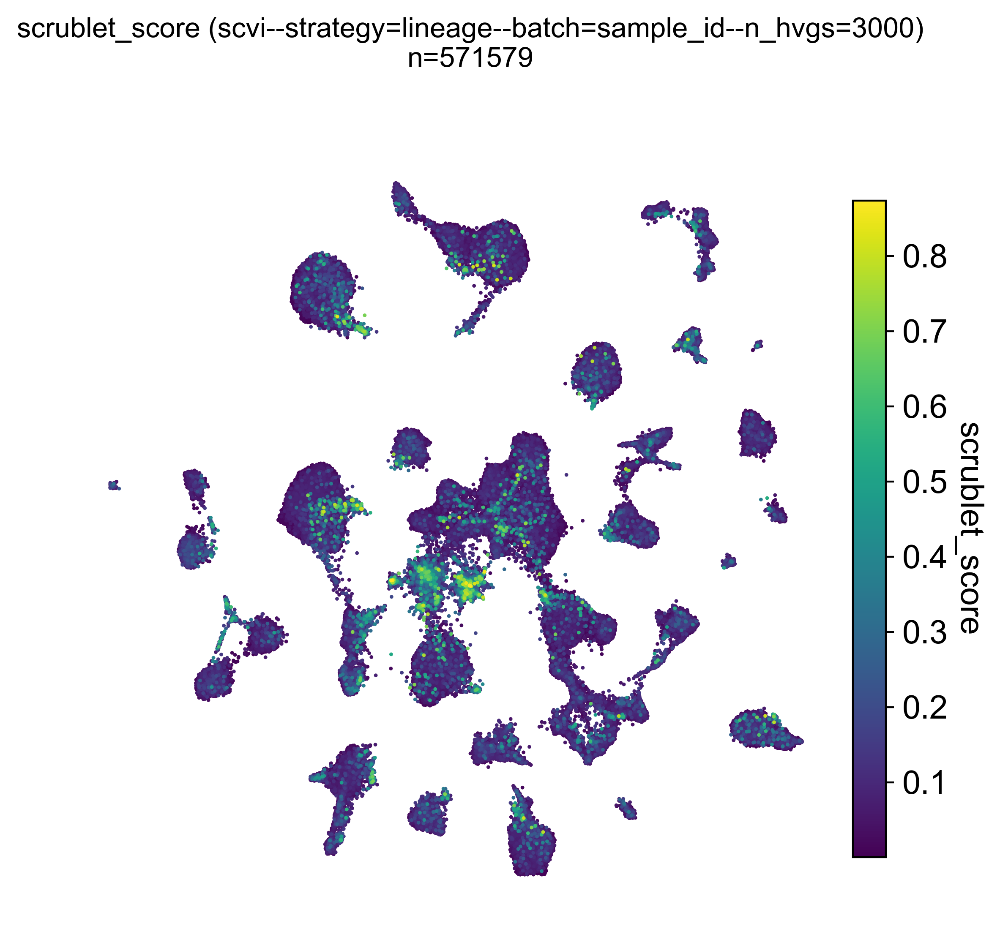

Plotting colors:   0%|          | 0/1 [00:00<?, ?it/s]

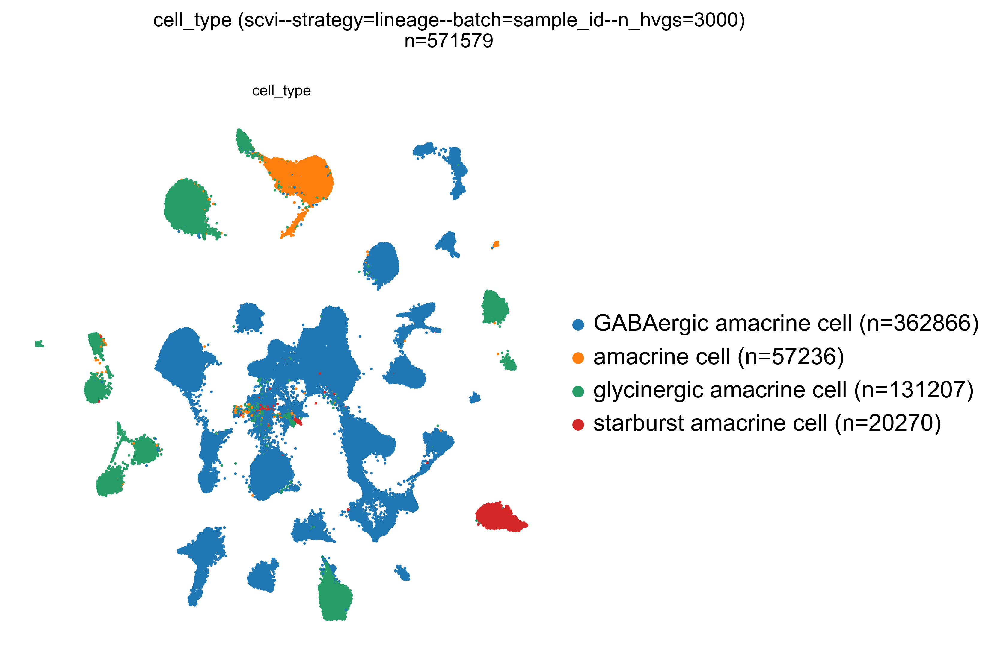

Plotting colors:   0%|          | 0/1 [00:00<?, ?it/s]

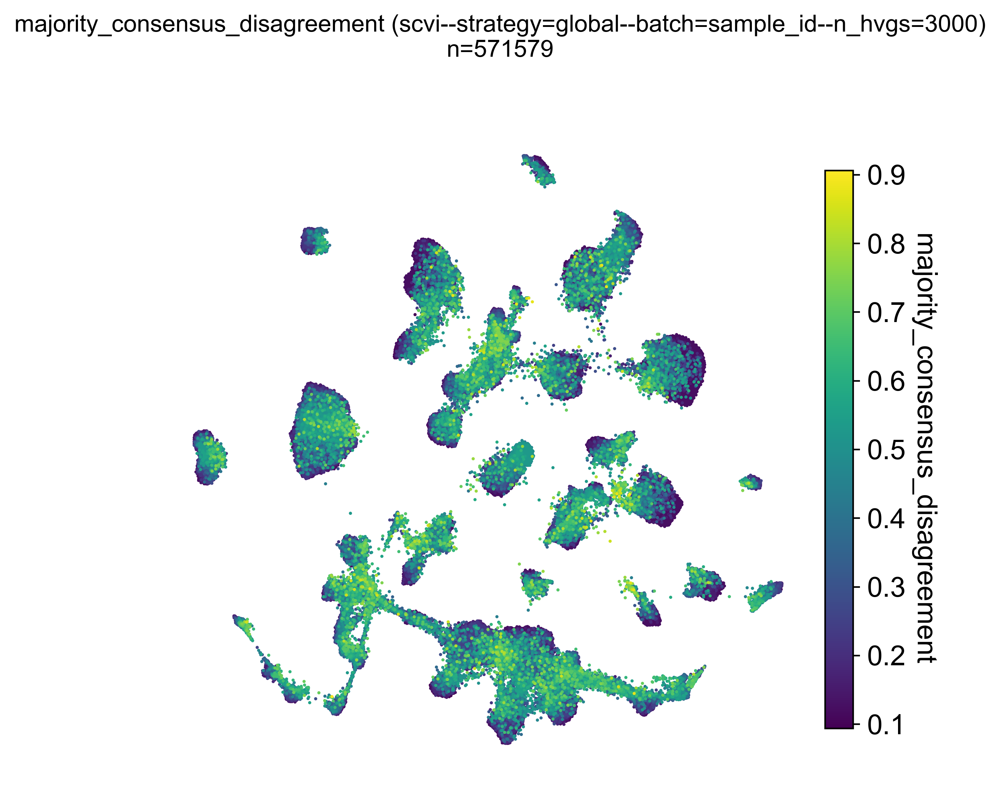

Plotting colors:   0%|          | 0/1 [00:00<?, ?it/s]

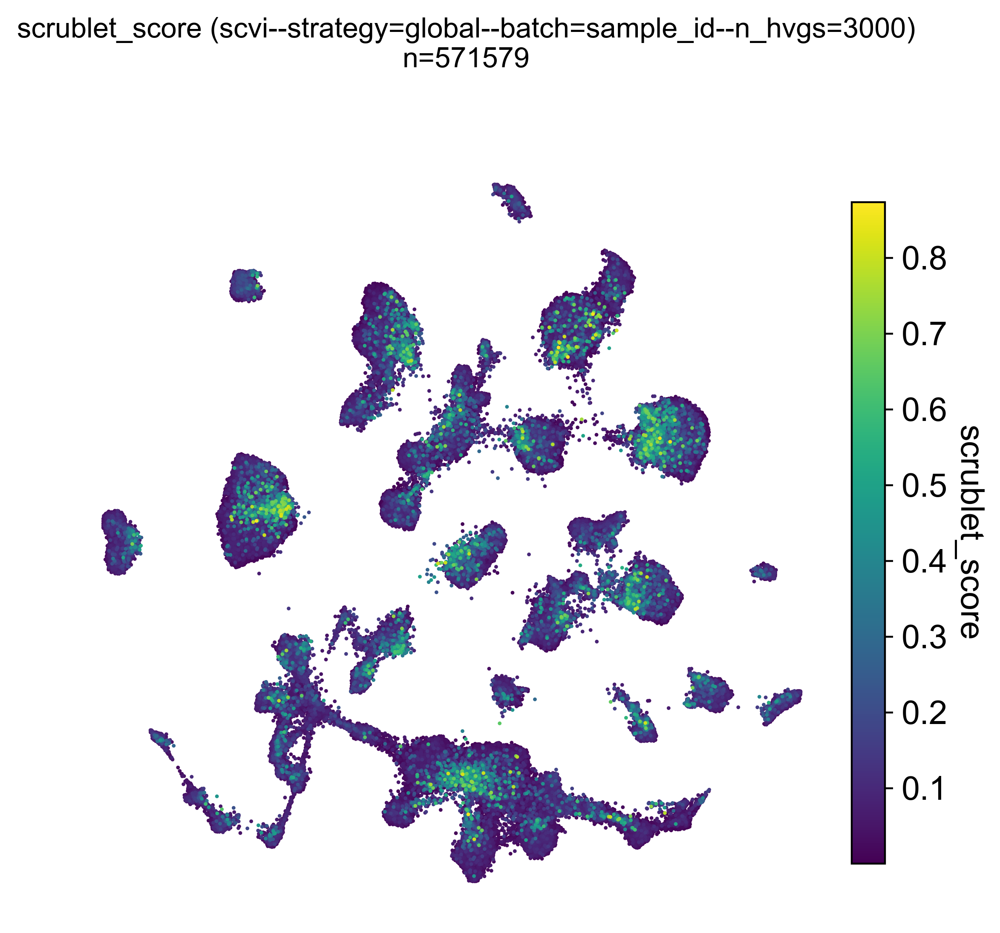

Plotting colors:   0%|          | 0/1 [00:00<?, ?it/s]

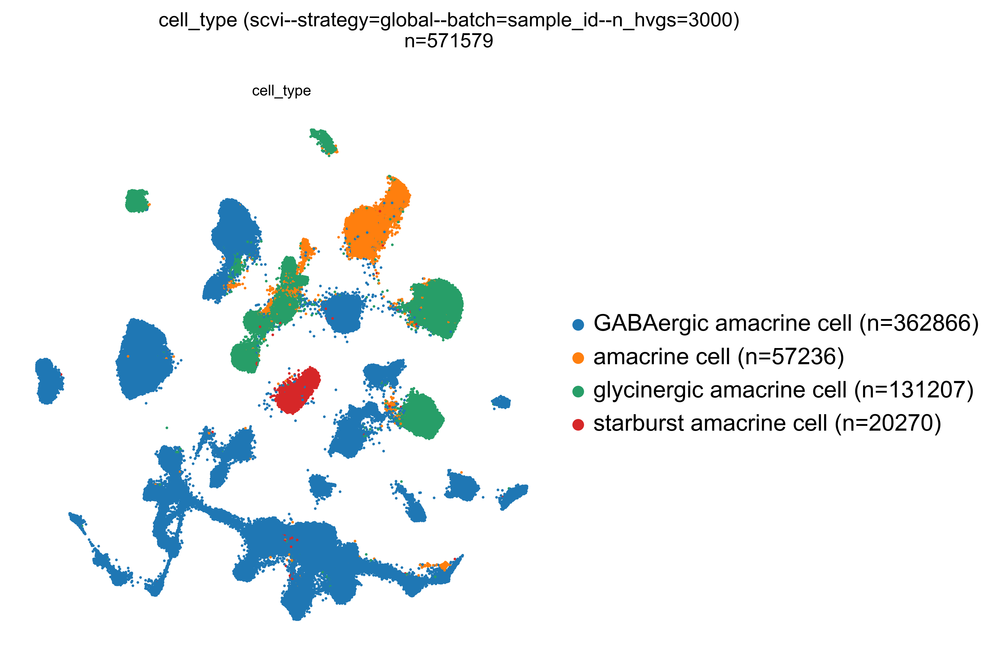

Plotting colors:   0%|          | 0/1 [00:00<?, ?it/s]

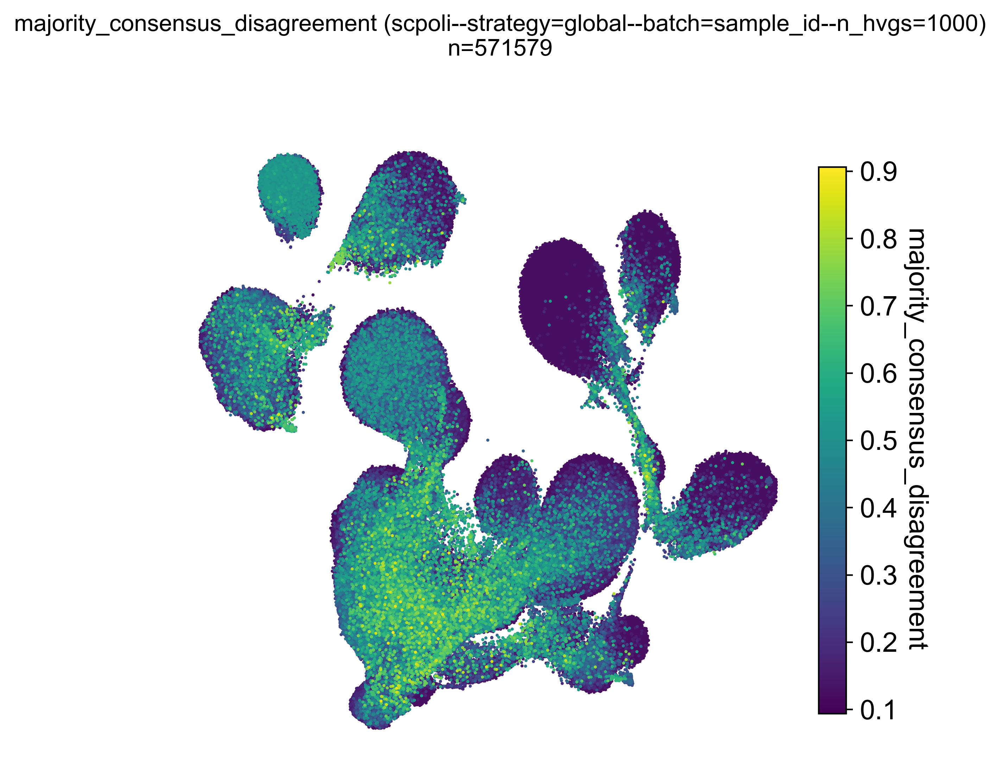

Plotting colors:   0%|          | 0/1 [00:00<?, ?it/s]

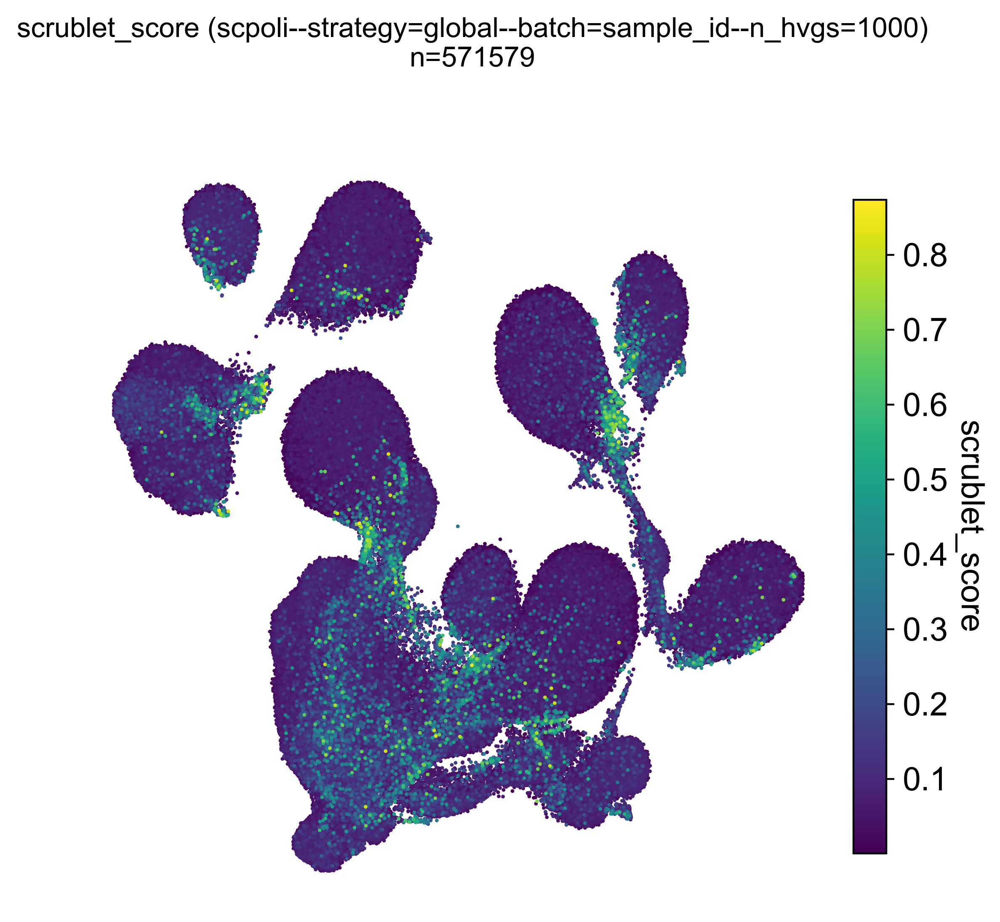

Plotting colors:   0%|          | 0/1 [00:00<?, ?it/s]

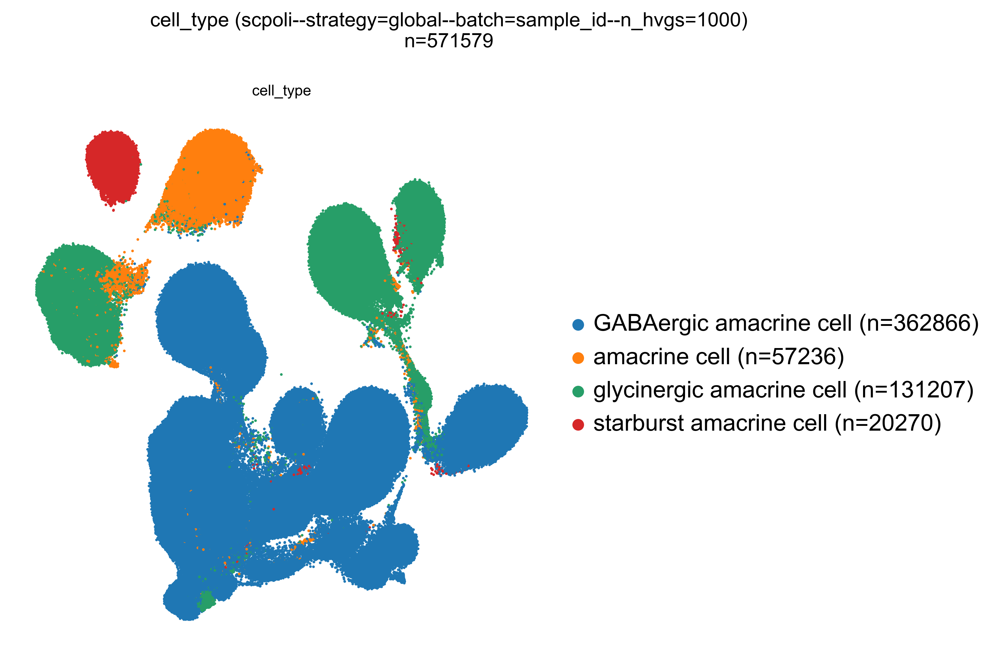

Plotting colors: 100%|██████████| 1/1 [00:09<00:00,  9.34s/it]


In [29]:
for integration in integrations:
    for color in colors:
        atl.pl.embedding(
            adata,
            basis=f'X_umap--{integration}',
            color=color,
            title=f'{color} ({integration})',
            size=10,
            output_dir=figure_dir,
            file_type='svg',
            file_prefix=f'Fig3F_{integration}_',
            verbose=False,
            legend_fontsize=14,
        )

## Doublet cluster

### Compare majority consensus vs scrublet score

In [ ]:
cluster_col = f'leiden_0.5_1--{integrations[1]}'

In [30]:
def scatterplot(adata, x, y, group_col):
    df = adata.obs.groupby(
        group_col, observed=True
    )[[x, y]].mean().sort_values(
        by=x,
    )
    ax = sns.scatterplot(data=df, x=x, y=y)
    ax.set_title(group_col)
    sns.despine(ax=ax)
    plt.show()

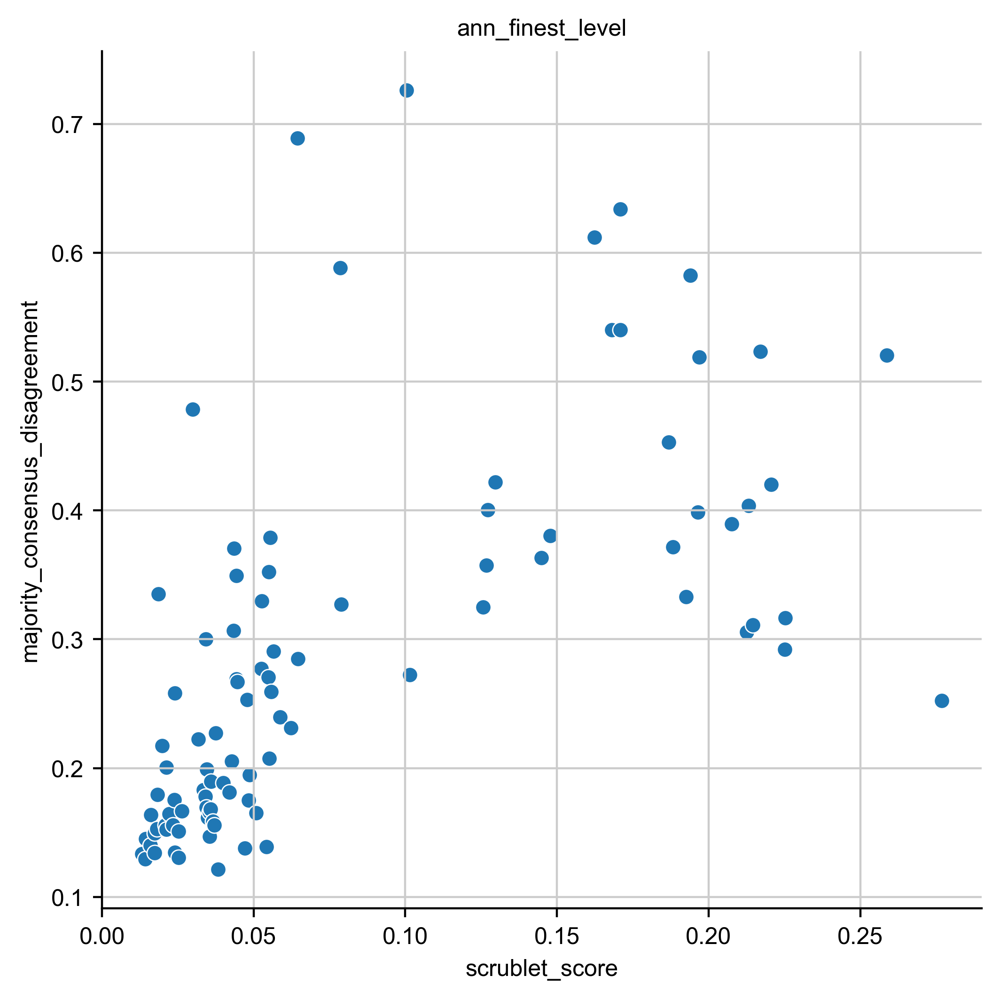

In [32]:
scatterplot(
    adata,
    'scrublet_score',
    'majority_consensus_disagreement',
    group_col='ann_finest_level'
)

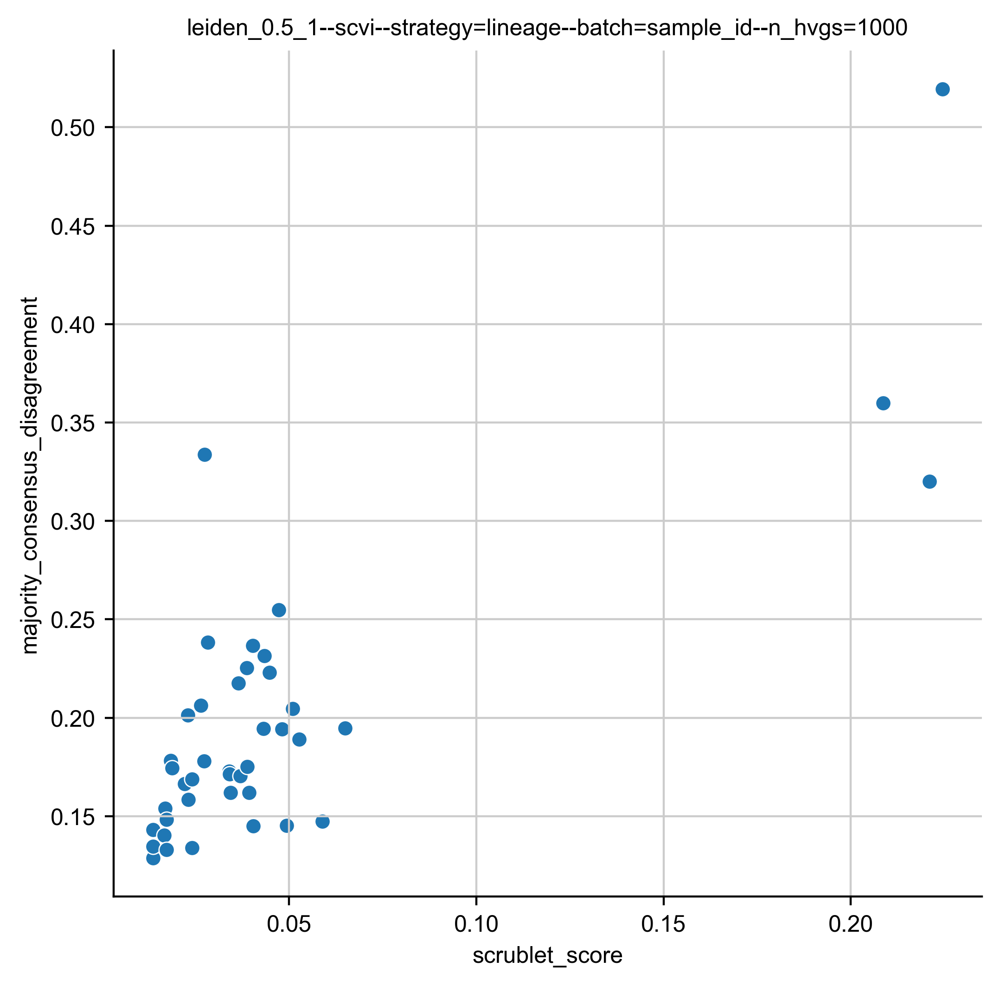

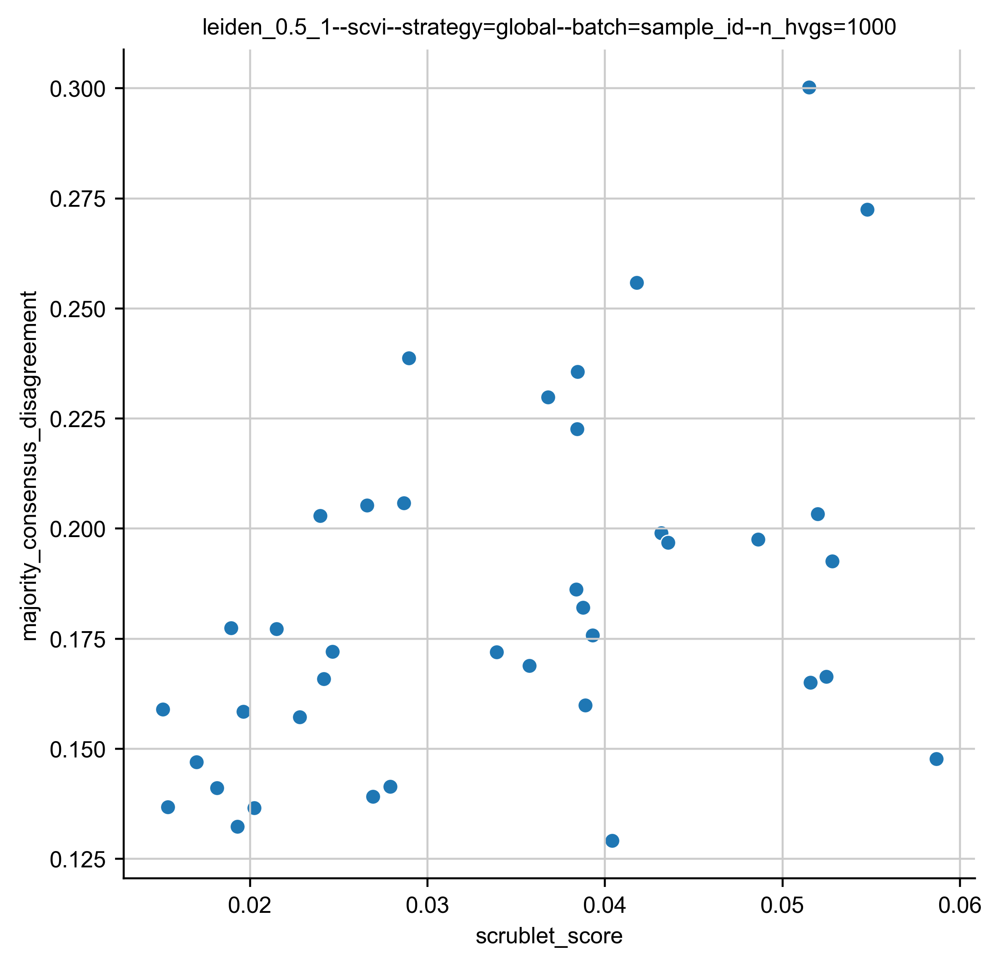

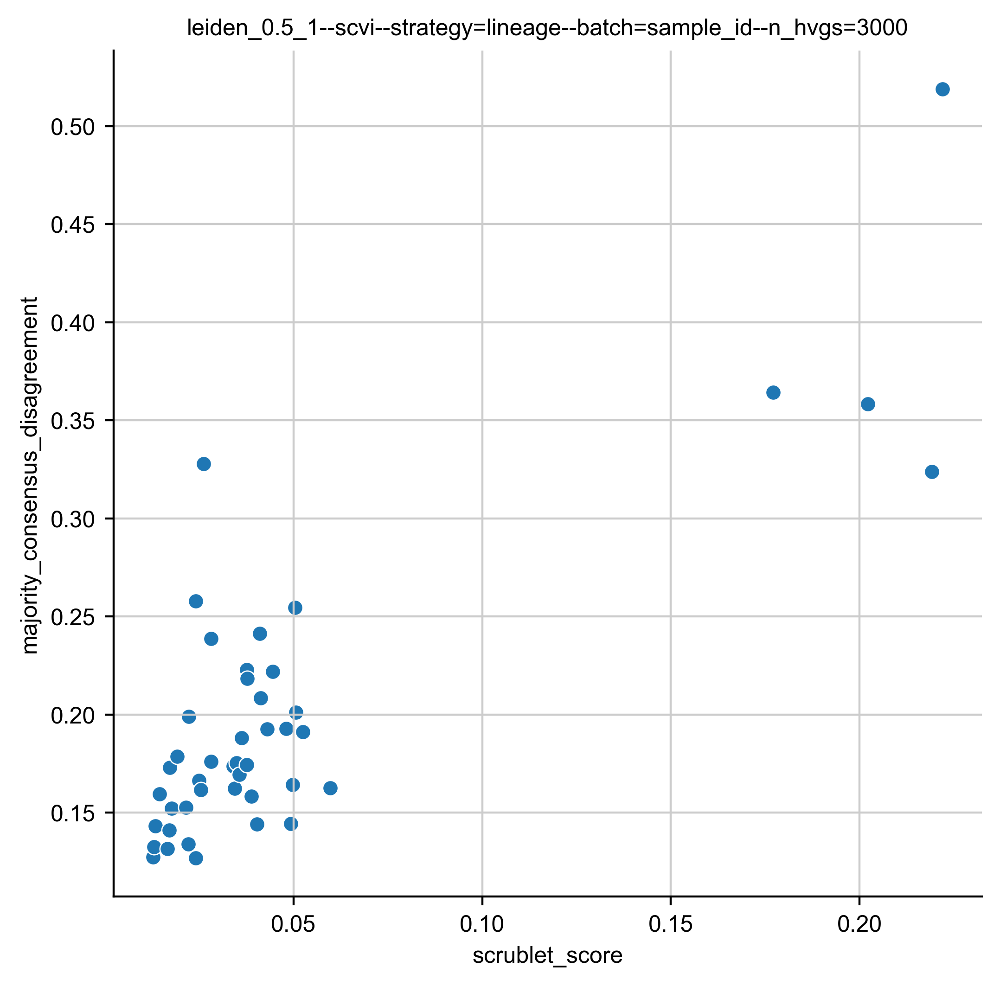

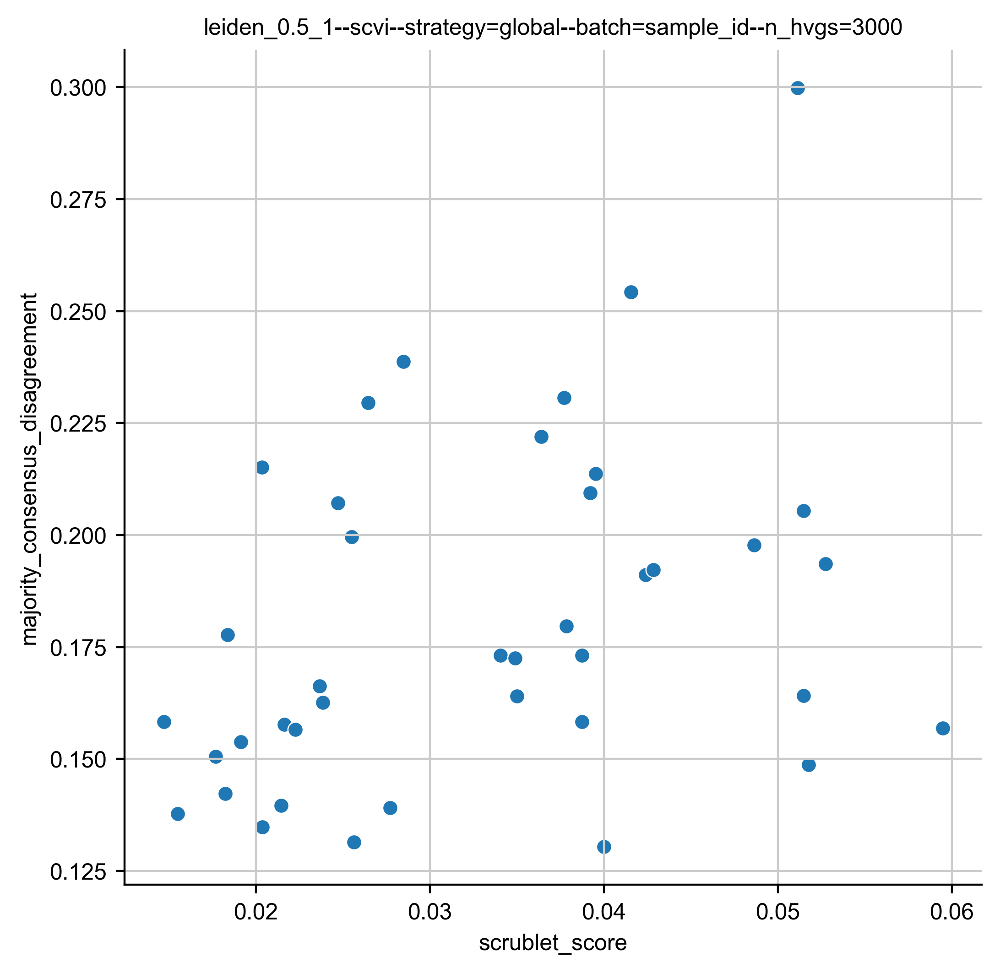

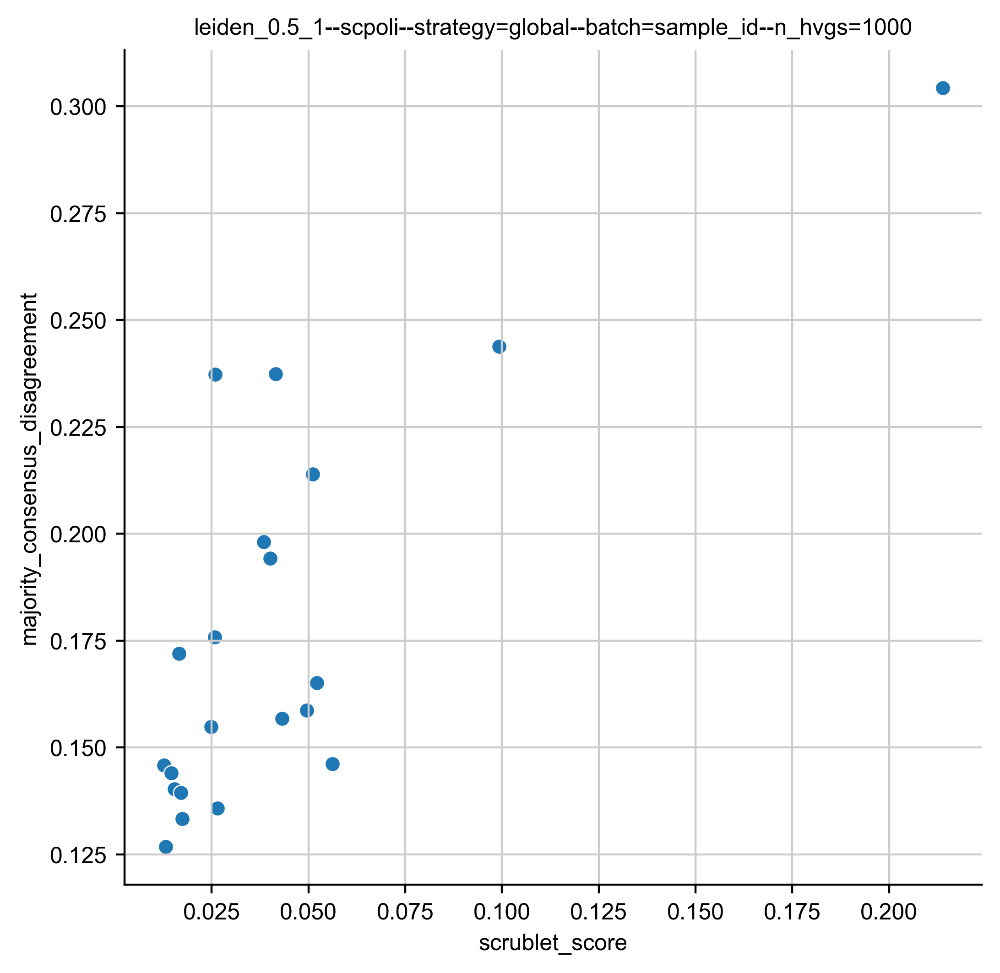

In [33]:
for integration in integrations:
    scatterplot(
        adata,
        'scrublet_score',
        'majority_consensus_disagreement',
        group_col=f'leiden_0.5_1--{integration}'
    )

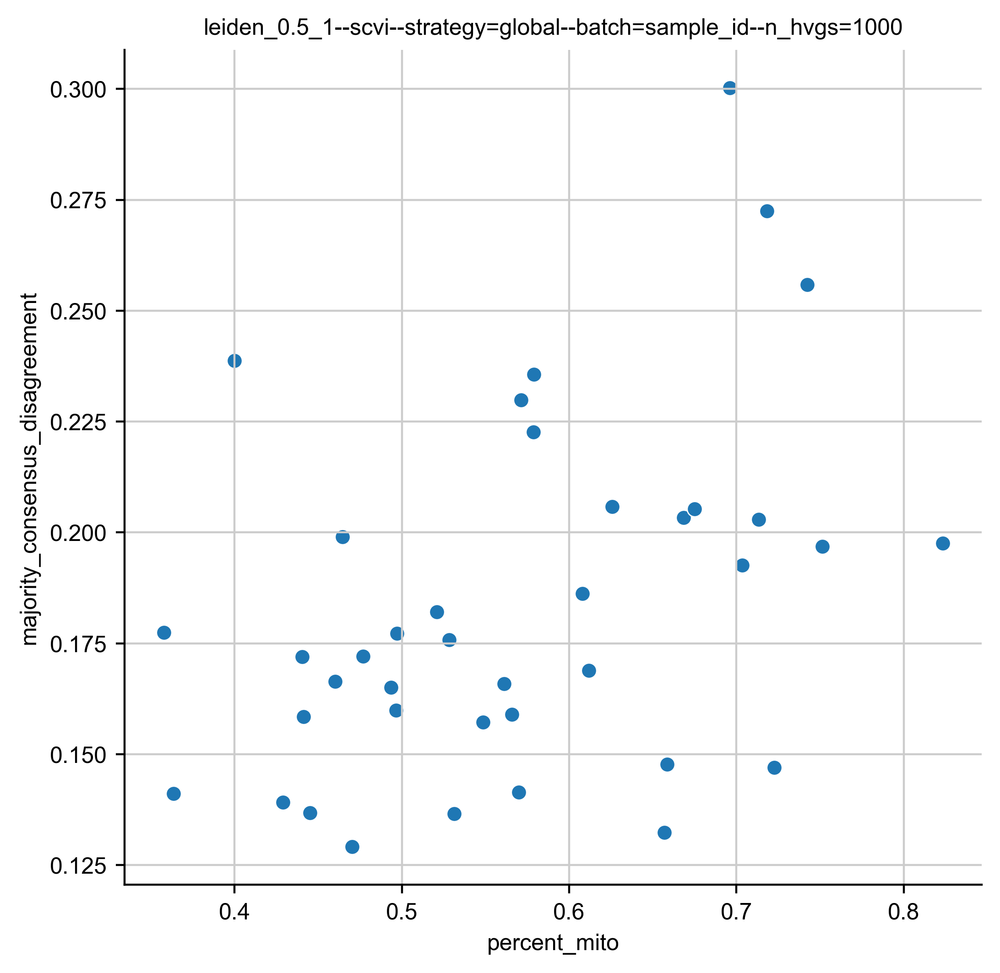

In [34]:
scatterplot(
    adata,
    group_col=cluster_col,
    x='percent_mito',
    y='majority_consensus_disagreement',
)

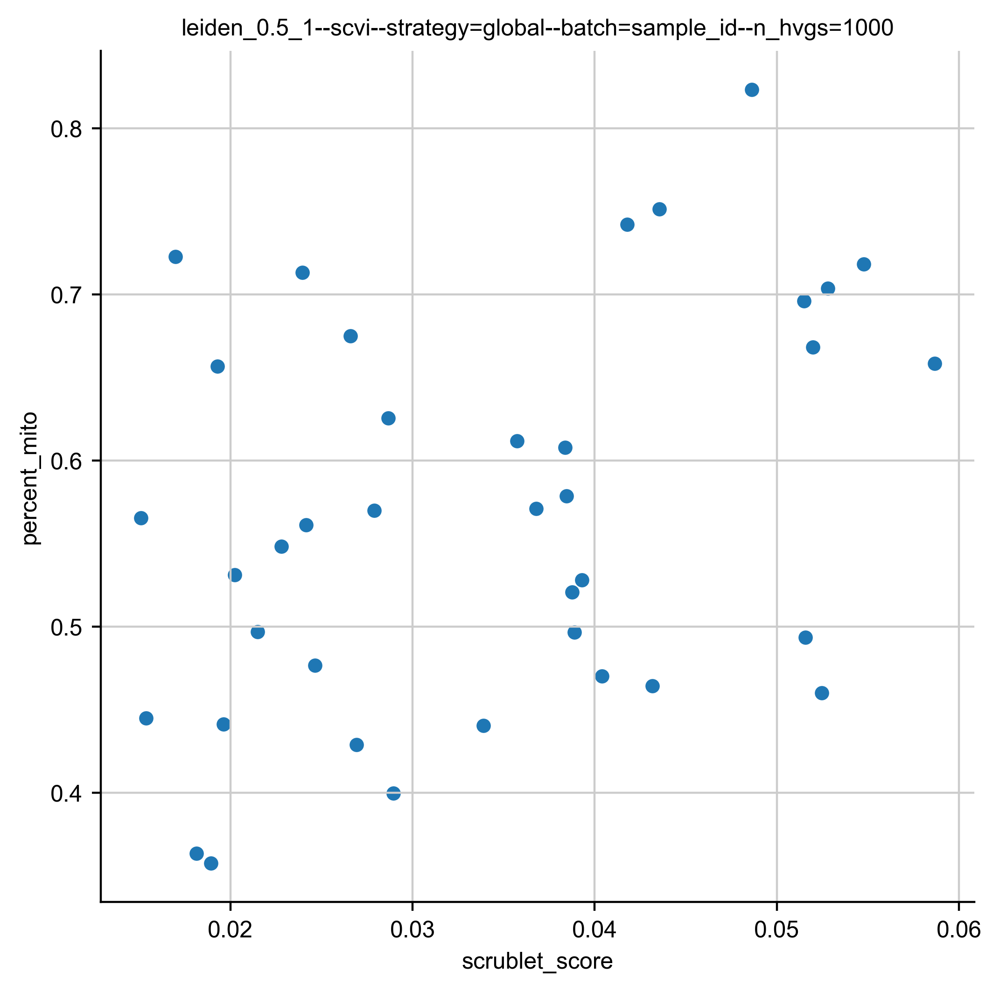

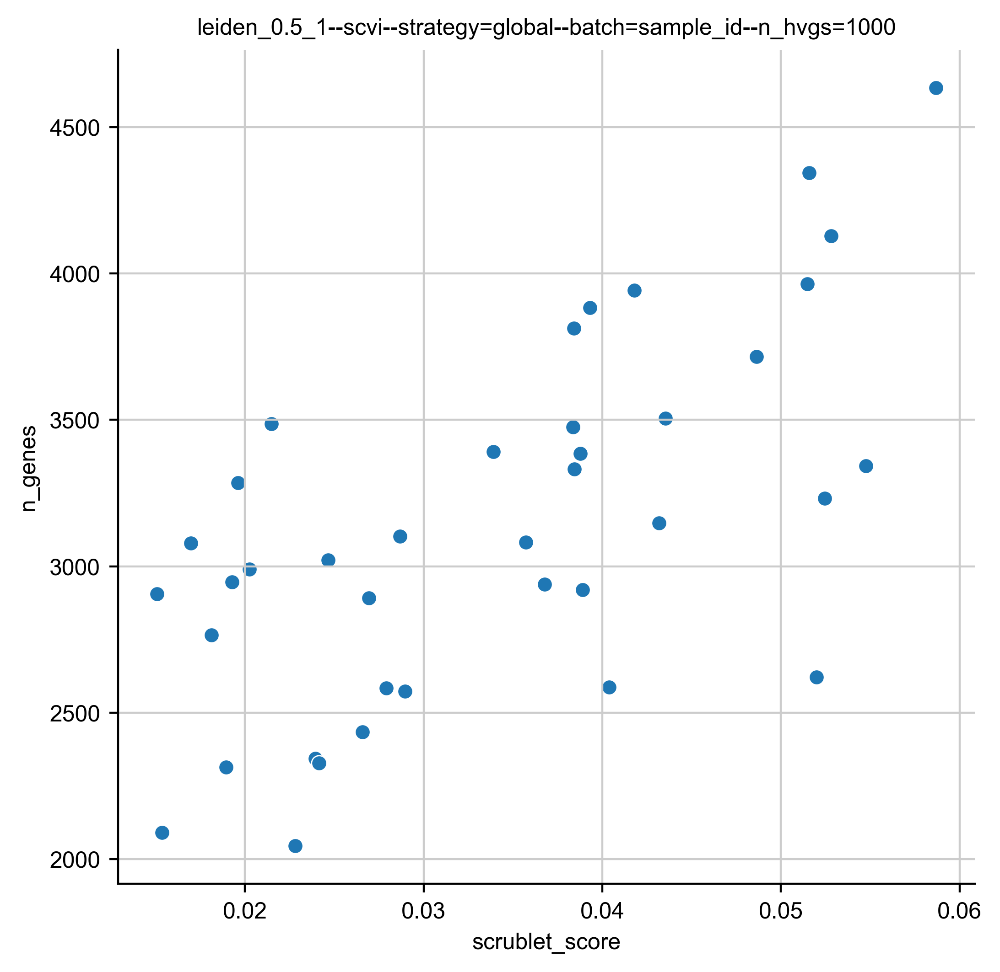

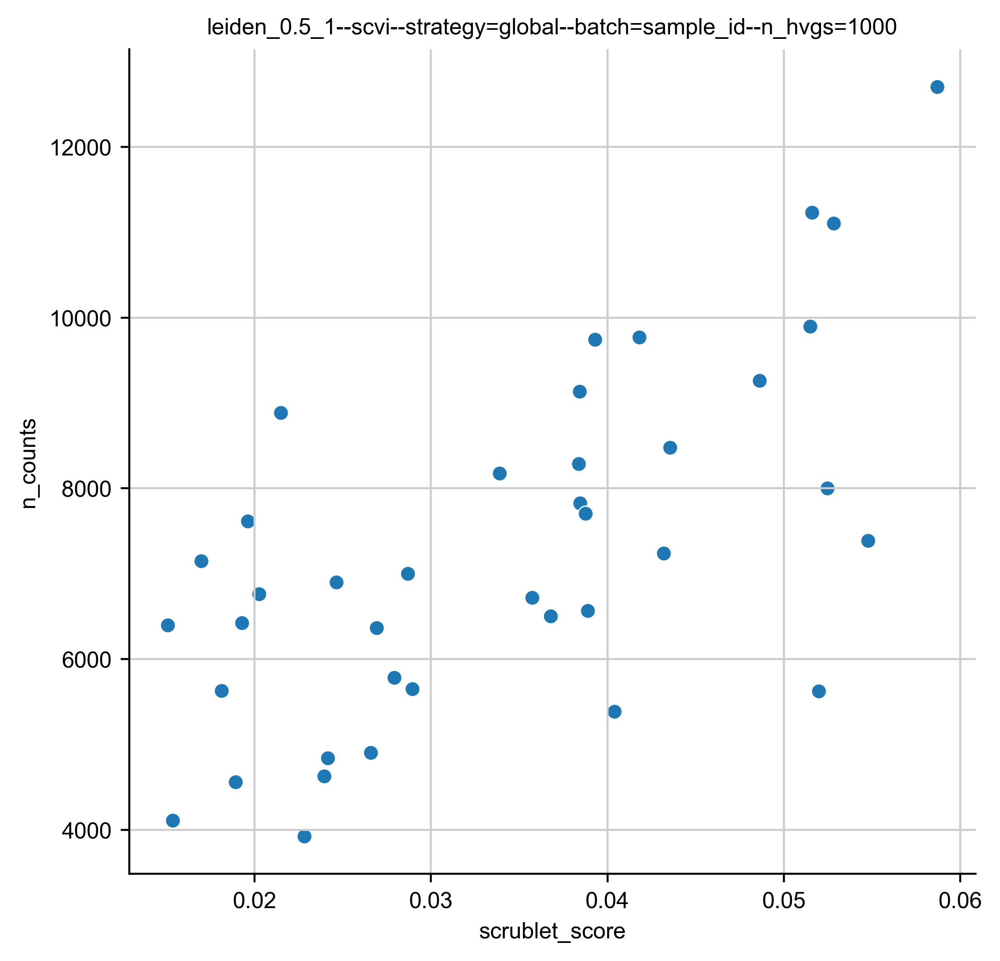

In [35]:
scatterplot(
    adata,
    group_col=cluster_col,
    x='scrublet_score',
    y='percent_mito'
)

scatterplot(
    adata,
    group_col=cluster_col,
    x='scrublet_score',
    y='n_genes'
)

scatterplot(
    adata,
    group_col=cluster_col,
    x='scrublet_score',
    y='n_counts'
)

In [11]:
def back_to_back_barplot(
    adata,
    group_col,
    left_col,
    right_col,
    figsize=(7, 8),
    title='',
    round_decimals=2,
    left_color='steelblue',
    right_color='tomato',
    scale=False,
):
    from matplotlib.ticker import FuncFormatter
    df = adata.obs.groupby(
        group_col, observed=True
    )[[left_col, right_col]].mean().sort_values(by=left_col)
    
    categories = df.index
    values_left  = df[left_col]
    values_right = df[right_col]

    if scale:
        plot_left  = -values_left  / values_left.max()
        plot_right =  values_right / values_right.max()
    else:
        plot_left  = -values_left
        plot_right =  values_right

    fig, ax = plt.subplots(figsize=figsize)
    ax.barh(categories, plot_left,  color=left_color,  label=left_col)
    ax.barh(categories, plot_right, color=right_color, label=right_col)

    # Fix tick labels to show original scale values
    if scale:
        left_max  = values_left.max()
        right_max = values_right.max()
        ax.xaxis.set_major_formatter(FuncFormatter(
            lambda x, _: f'{abs(x) * (left_max if x < 0 else right_max):.{round_decimals}g}'
        ))
    else:
        ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f'{abs(x):.{round_decimals}g}'))

    ax.axvline(0, color='black', linewidth=0.8)

    # Color tick labels and ticks per side
    fig.canvas.draw()
    for tick in ax.xaxis.get_major_ticks():
        tick_value = tick.get_loc()
        color = left_color if tick_value < 0 else right_color if tick_value > 0 else 'black'
        tick.label1.set_color(color)
        tick.tick1line.set_color(color)

    ax.annotate(left_col,  xy=(0.25, -0.05), xycoords='axes fraction', ha='center', va='top', color=left_color)
    ax.annotate(right_col, xy=(0.75, -0.05), xycoords='axes fraction', ha='center', va='top', color=right_color)
    ax.set_ylabel(group_col, labelpad=15)
    ax.set_title(title)

    ax.set_axisbelow(True)
    ax.spines[['top', 'right']].set_visible(False)
    ax.margins(y=0)
    plt.tight_layout()
    plt.show()

In [ ]:
back_to_back_barplot(
    adata,
    cluster_col,
    'majority_consensus_disagreement',
    'scrublet_score',
    title='Label-based cluster disagreement',
    figsize=(5,5),
)
plt.savefig(figure_dir / '3F_back_to_back_disagreement_scrublet.svg')

NameError: name 'cluster_col' is not defined

In [ ]:
back_to_back_barplot(
    adata,
    'ann_finest_level',
    'majority_consensus_disagreement',
    'scrublet_score',
    figsize=(7, 15),
)

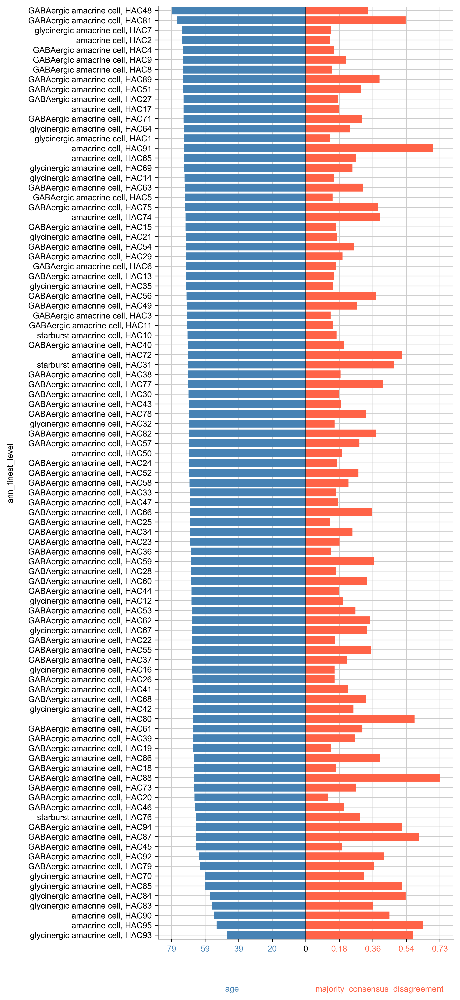

In [39]:
back_to_back_barplot(
    adata,
    'ann_finest_level',
    'age',
    'majority_consensus_disagreement',
    figsize=(7, 15),
    scale=True,
)

INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


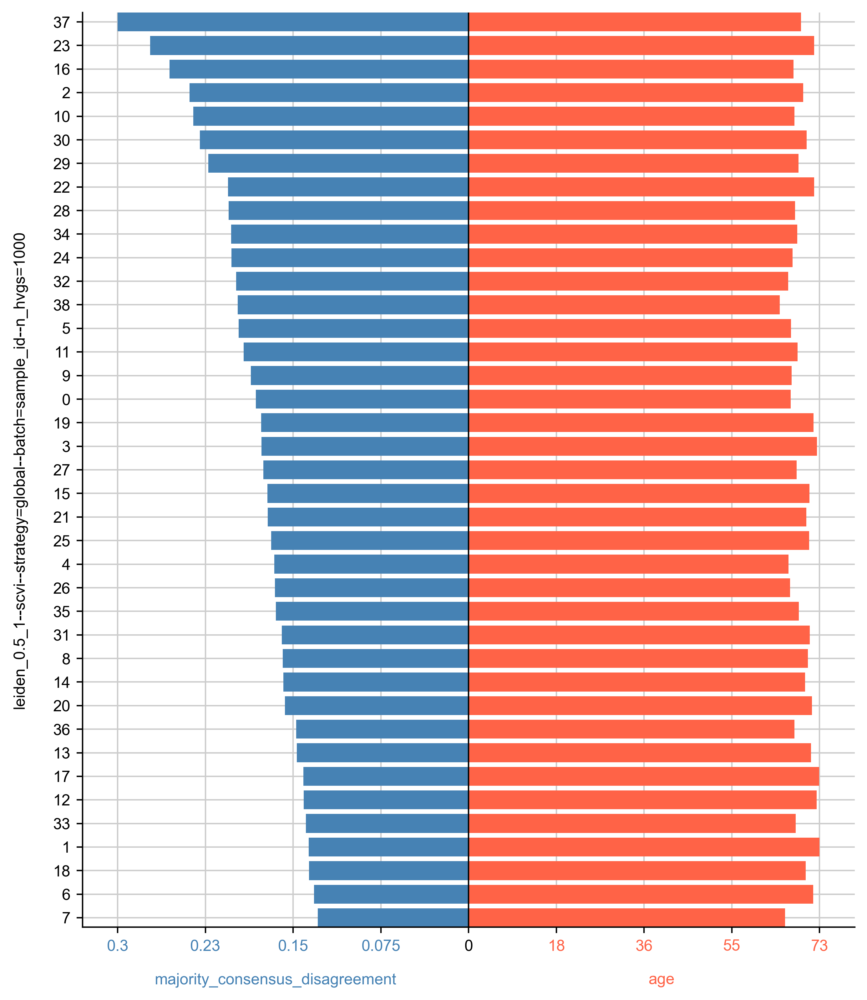

In [40]:
back_to_back_barplot(adata, cluster_col, 'majority_consensus_disagreement', 'age', scale=True)

INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


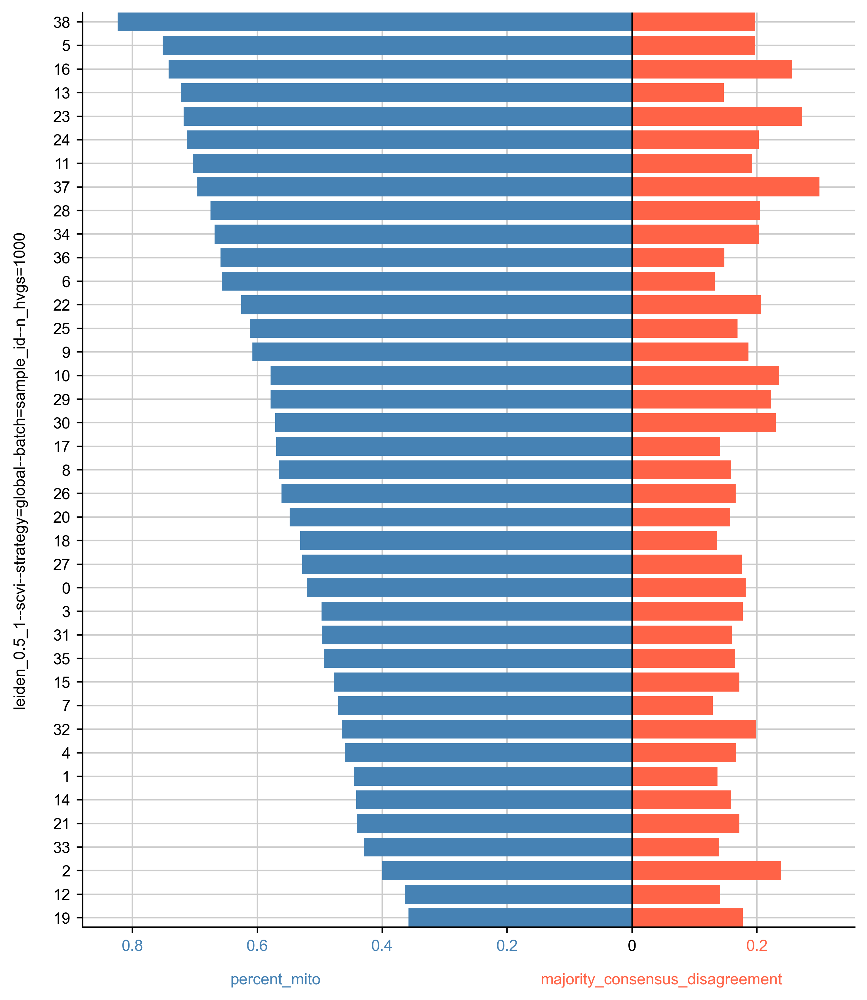

In [41]:
back_to_back_barplot(adata, cluster_col, 'percent_mito', 'majority_consensus_disagreement')

INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


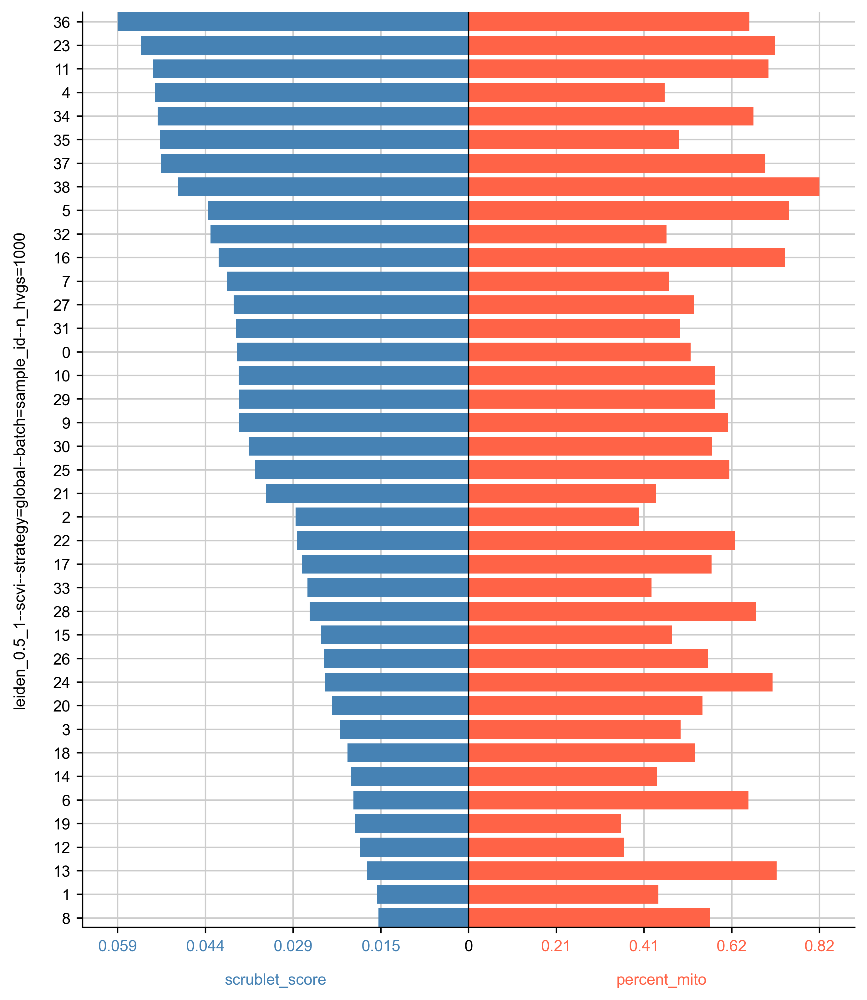

In [42]:
back_to_back_barplot(adata, cluster_col, 'scrublet_score', 'percent_mito', scale=True)

INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


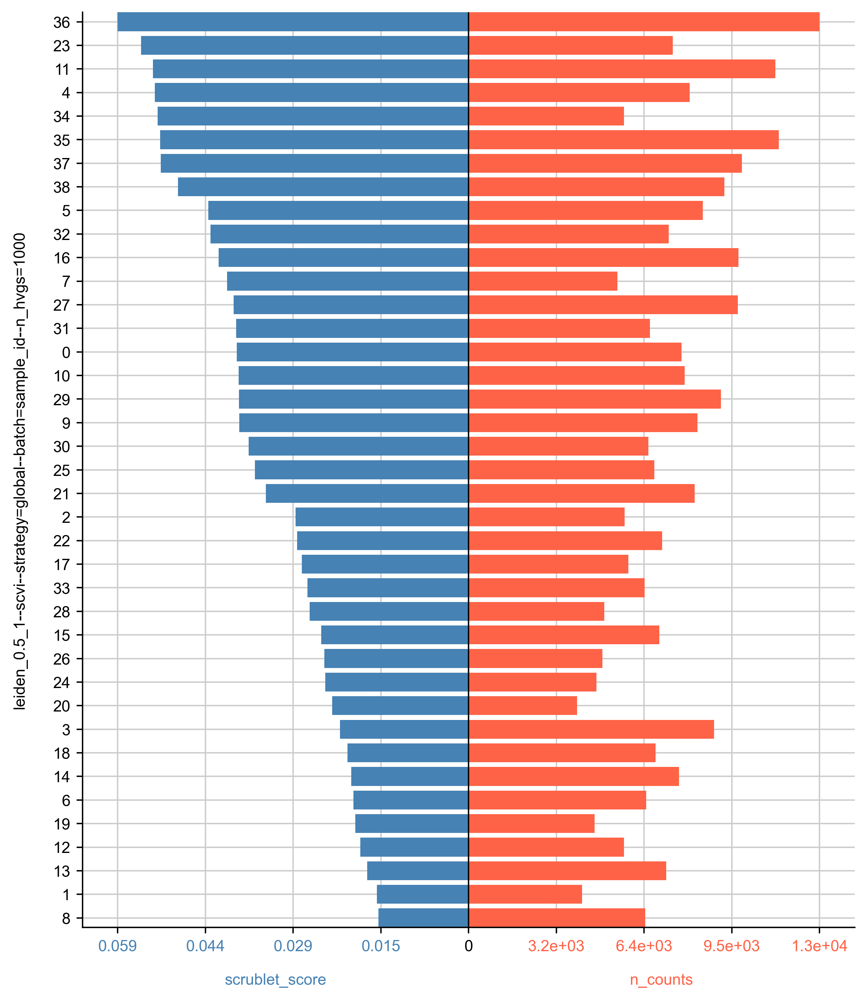

In [43]:
back_to_back_barplot(adata, cluster_col, 'scrublet_score', 'n_counts', scale=True)

### Follow up doublet cluster

In [44]:
groups = ['22', '42', '21', '17']
obs_mask = adata.obs[cluster_col].isin(groups)

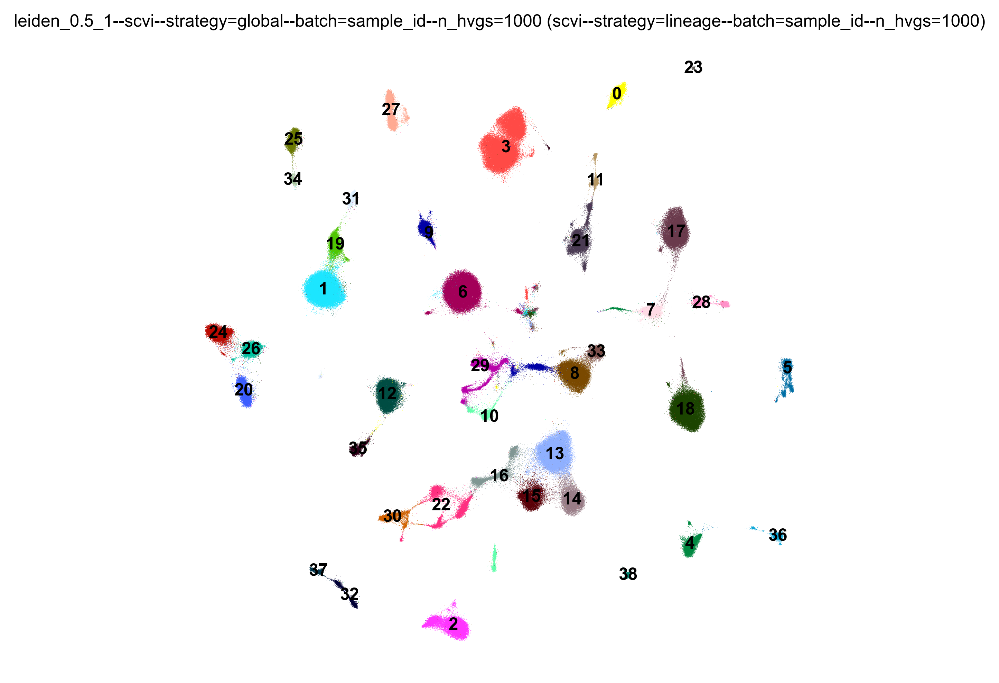

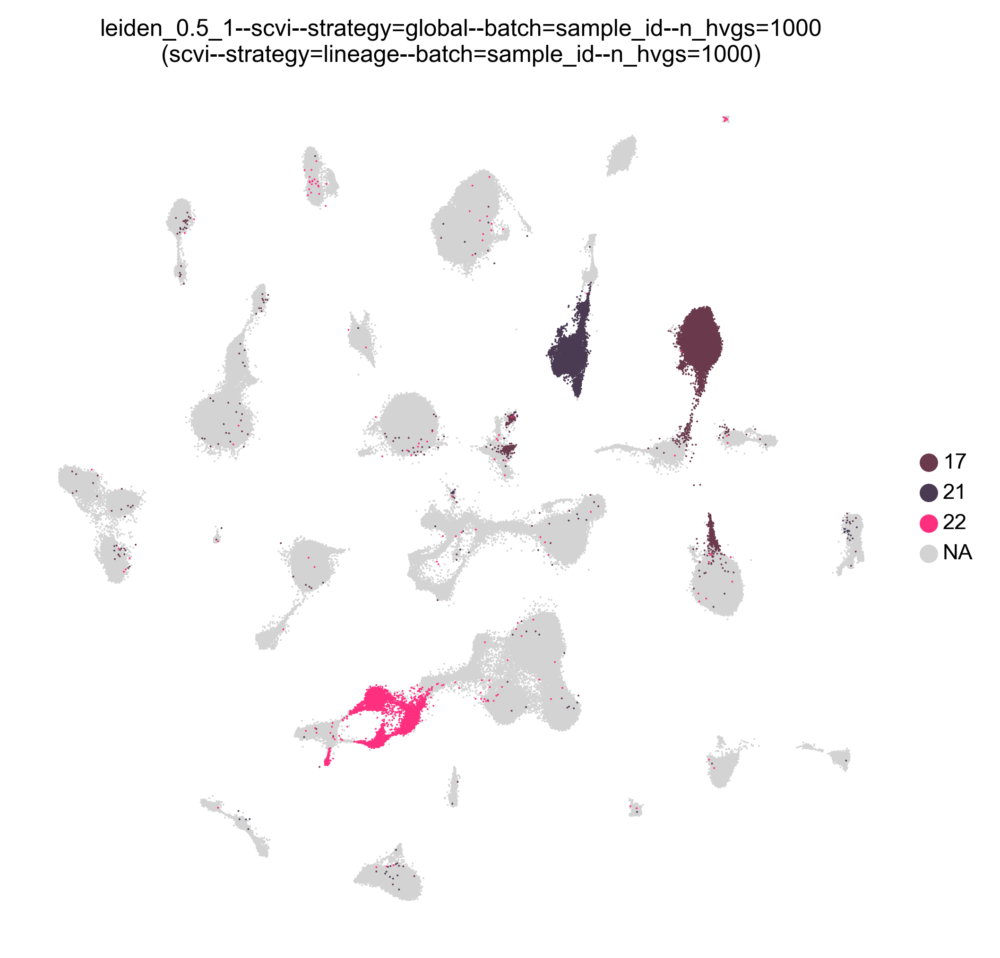

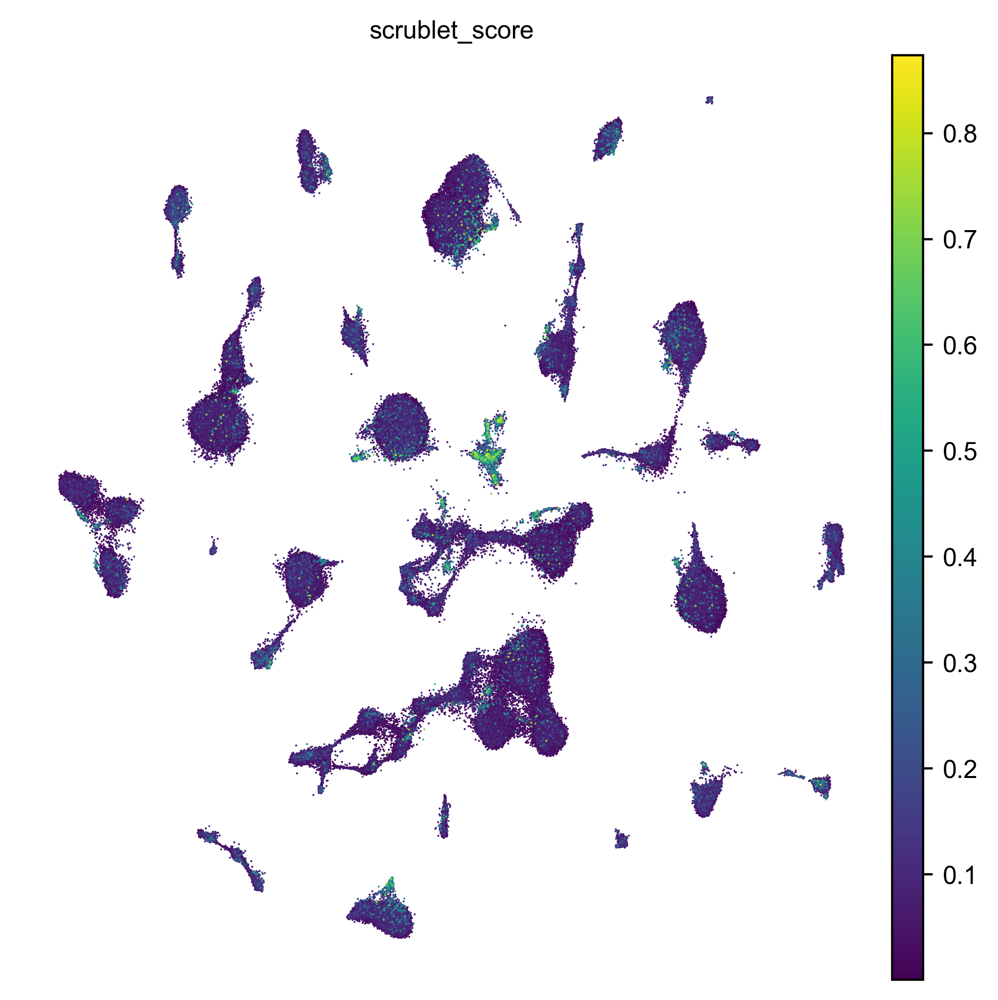

In [ ]:
for integration in integrations[:2]:
    sc.pl.embedding(
        adata,
        basis=f'X_umap--{integration}',
        color=cluster_col,
        title=f'{cluster_col} ({integration})',
        legend_loc='on data',
    )
    
    sc.pl.embedding(
        adata,
        basis=f'X_umap--{integration}',
        color=cluster_col,
        groups=groups,
        title=f'{cluster_col}\n({integration})',
        size=2,
    )
    sc.pl.embedding(
        adata,
        basis=f'X_umap--{integration}',
        color='scrublet_score',
        # mask_obs=obs_mask,
        size=2,
    )

### Graph dissimilarity

In [ ]:
from scatlastb_utils.metrics import compare_distances, plot_distances_scatter, plot_ranked_distances

In [ ]:
integrations

In [ ]:
integration1, integration2 = integrations[0], integrations[1]

In [ ]:
%%time
comp = f'{integration1}-vs-{integration2}'

adata.obs[[
    f'avg_distance_1:{comp}',
    f'avg_distance_2:{comp}',
    f'avg_difference:{comp}',
    f'avg_distance_diff:{comp}',
    f'spearman_correlation:{comp}',
]] = compare_distances(
    adata,
    obsp_connectivities_1=f'connectivities--{integration1}',
    obsp_distances_1=f'distances--{integration1}',
    obsm_key_1=f'X_emb--{integration1}',
    obsp_connectivities_2=f'connectivities--{integration2}',
    obsp_distances_2=f'distances--{integration2}',
    obsm_key_2=f'X_emb--{integration2}',
    scale_distances=True,
)

comp = f'{integration2}-vs-{integration1}'
adata.obs[[
    f'avg_distance_1:{comp}',
    f'avg_distance_2:{comp}',
    f'avg_difference:{comp}',
    f'avg_distance_diff:{comp}',
    f'spearman_correlation:{comp}',
]] = compare_distances(
    adata,
    obsp_connectivities_1=f'connectivities--{integration2}',
    obsp_distances_1=f'distances--{integration2}',
    obsm_key_1=f'X_emb--{integration2}',
    obsp_connectivities_2=f'connectivities--{integration1}',
    obsp_distances_2=f'distances--{integration1}',
    obsm_key_2=f'X_emb--{integration1}',
    scale_distances=True,
)

In [ ]:
def plot_graph_dissimilarity_umap(
    adata,
    integration1,
    integration2,
    metric,
    **kwargs,
):
    comparisons = [
        f'{integration1}-vs-{integration2}',
        f'{integration2}-vs-{integration1}'
    ]
    colors = [f'{metric}:{comparison}' for comparison in comparisons]
    ncols = len(comparisons)
    
    sc.pl.embedding(
        adata,
        basis=f'X_umap--{integration1}',
        color=colors,
        ncols=ncols,
        wspace=0.5,
        **kwargs,
    )
 
    sc.pl.embedding(
        adata,
        basis=f'X_umap--{integration2}',
        color=colors,
        ncols=ncols,
        wspace=0.5,
        **kwargs,
    )

In [ ]:
plot_ranked_distances(adata, integration1, integration2)
plot_distances_scatter(adata, integration1, integration2, s=1, alpha=0.5)
plot_distances_scatter(adata, integration2, integration1, s=1, alpha=0.5)

In [ ]:
plot_graph_dissimilarity_umap(
    adata,
    integration1,
    integration2,
    metric='avg_distance_diff',
    cmap='viridis',
    size=2,
    vmin=0,
)

In [ ]:
plot_graph_dissimilarity_umap(
    adata,
    integration1,
    integration2,
    metric='spearman_correlation',
    size=20,
    # add_outline=True,
    cmap="viridis_r",
    vcenter=0,
    mask_obs=adata.obs.filter(like='spearman_correlation').lt(0).all(axis=1),
    sort_order=False,
)

### Subset to doublet cluster

In [ ]:
leiden_colors = [
    'ann_finest_level',
    'majority_consensus',
    'cell_type', 
    # 'scrublet_score',
    # 'percent_mito',
    # 'n_genes',
    # 'n_counts',
]

In [ ]:
_ad = adata[obs_mask].copy()

In [ ]:
for integration in integrations[:2]:
    rsc.pp.neighbors(_ad, use_rep=f'X_emb--{integration}')
    rsc.tl.umap(_ad)
    _ad.obsm[f'X_umap--{integration}'] = _ad.obsm['X_umap']

In [ ]:
for color in leiden_colors:
    for integration in integrations[:2]:
        # if _ad.obs[color].dtype == 'category':
        #     _ad.obs[color] = _ad.obs[color].cat.remove_unused_categories()
        sc.pl.embedding(
            _ad,
            basis=f'X_umap--{integration}',
            color=color,
            title=f'{color} ({integration})',
            palette=sc.pl.palettes.default_102,
        )

## Metrics

In [ ]:
metrics_df = pd.concat(
    adata.uns[key]
    for key in adata.uns.keys()
    if key.startswith('metrics--')
)

In [ ]:
metrics_df

In [ ]:
metrics_df['strategy'] = metrics_df['file_id'].str.split('=').str[1]

In [ ]:
metrics_df.query('metric == "M\'s I gs:AC_starburst"').value_counts(['strategy', 'score'])

In [ ]:
sns.catplot(
    metrics_df.query('metric == "M\'s I gs:AC_starburst"'),
    y='score',
    x='strategy',
    hue='integration_method',
    palette='turbo',
    aspect=0.7,
    width=1,
)

In [ ]:
metrics_df.query('metric == "M\'s I:age"')['score']

In [ ]:
for metric in metrics_df['metric'].unique():
    try:
        g = sns.catplot(
            metrics_df.query('metric == @metric'),
            y='score',
            x='strategy',
            hue='integration_method',
            palette='turbo',
            aspect=0.7,
            width=4,
        )
        g.figure.suptitle(metric)
        # plt.tight_layout()
    except:
        print(metric, 'failed')

## Cell cycle effect

In [ ]:
cc_colors = ['S_score', 'G2M_score', 'phase']

In [ ]:
gene_mask = adata.var_names.isin(cell_cycle_genes['gene_id']) | adata.var['integration_features']
adata = adata[:, gene_mask].copy()

In [ ]:
adata = atl.utils.dask_compute(adata, layers='X')

In [ ]:
sc.tl.score_genes_cell_cycle(
    adata,
    s_genes=cell_cycle_genes.query('phase == "S"')['gene_id'],
    g2m_genes=cell_cycle_genes.query('phase == "G2/M"')['gene_id'],
)

In [ ]:
for integration in integrations:
    sc.pl.embedding(
        adata,
        basis=f'X_umap--{integration}',
        color=cc_colors,
        title=[f'{color} ({integration})' for color in cc_colors],
        size=10,
        palette=sc.pl.palettes.default_102,
    )

In [ ]:
label_key = 'cell_type'
for label in adata.obs[label_key].unique():
    _ad = adata[adata.obs[label_key] == label].copy()
    for integration in integrations:
        rsc.pp.neighbors(_ad, use_rep=f'X_emb--{integration}')
        rsc.tl.umap(_ad)
        sc.pl.umap(
            _ad,
            color=cc_colors,
            title=[f'{color} ({integration})\n{label_key}={label}\nn={_ad.n_obs}' for color in cc_colors],
            size=10,
            palette=sc.pl.palettes.default_102,
        )
        # sc.pl.embedding(
        #     adata,
        #     basis=f'X_umap--{integration}',
        #     color=cc_colors,
        #     title=[f'{color} ({integration})' for color in cc_colors],
        #     mask_obs=adata.obs['majority_consensus'] == label,
        #     size=10,
        #     palette=sc.pl.palettes.default_102,
        # )

TODO:
* compute PC-reg comparison per cell type
* rank cell type by PC-reg scores (per method)
* show top-performer

In [ ]:
for integration in integrations[:2]:
    sc.pl.embedding(
        _ad,
        basis=f'X_umap--{integration}',
        color=cc_colors,
        title=[f'{color} ({integration})' for color in cc_colors],
        palette=sc.pl.palettes.default_102,
    )